In [1]:
import pandas as pd

df = pd.read_csv(r"D:\2026\MedCare\ML\Dataset\Clean\ml_dataset_long.csv")

print("Shape:", df.shape)

Shape: (44632, 40)


In [2]:
print("Danh sách biến:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

Danh sách biến:
1. HHIDPN
2. RAGENDER
3. AGEY_B
4. HEIGHT
5. WEIGHT
6. PMBMI
7. PMWAIST
8. BPSYS
9. BPDIA
10. BPPULS
11. SMOKEV
12. SMOKEN
13. VGACTX
14. MDACTX
15. LTACTX
16. DRINK
17. DRINKD
18. DRINKN
19. SLEEP
20. SLEEPE
21. SLEEPFAL
22. SLEEPSN
23. SLEEPBR
24. HIBP
25. HIBPS
26. HIBPE
27. ARTHR
28. ARTHRE
29. ARTHRS
30. DRUGS
31. BPMED
32. HIGHCHOL
33. IS_SOB
34. SOB
35. CHOLMED
36. MENOPAUSE
37. ITOT
38. T2D
39. CVD
40. WAVE


In [3]:
import pandas as pd

path = r"D:\2026\MedCare\ML\Dataset\Clean\merged_labeled.csv"
df = pd.read_csv(path)

labels = [f"R{w}{d}" for w in range(13, 17) for d in ["T2D", "CVD"]]

result = pd.DataFrame({
    col: [
        (df[col] == 0).sum(),
        (df[col] == 1).sum(),
        df[col].isna().sum()
    ]
    for col in labels
}, index=["Không bệnh (0)", "Có bệnh (1)", "Thiếu (NaN)"]).T

result["Tổng"] = result.sum(axis=1)

print(result)

        Không bệnh (0)  Có bệnh (1)  Thiếu (NaN)   Tổng
R13T2D            8300         2858            0  11158
R13CVD            8536         2622            0  11158
R14T2D            8011         3147            0  11158
R14CVD            8256         2902            0  11158
R15T2D            7757         3401            0  11158
R15CVD            7963         3195            0  11158
R16T2D            7464         3694            0  11158
R16CVD            7540         3618            0  11158


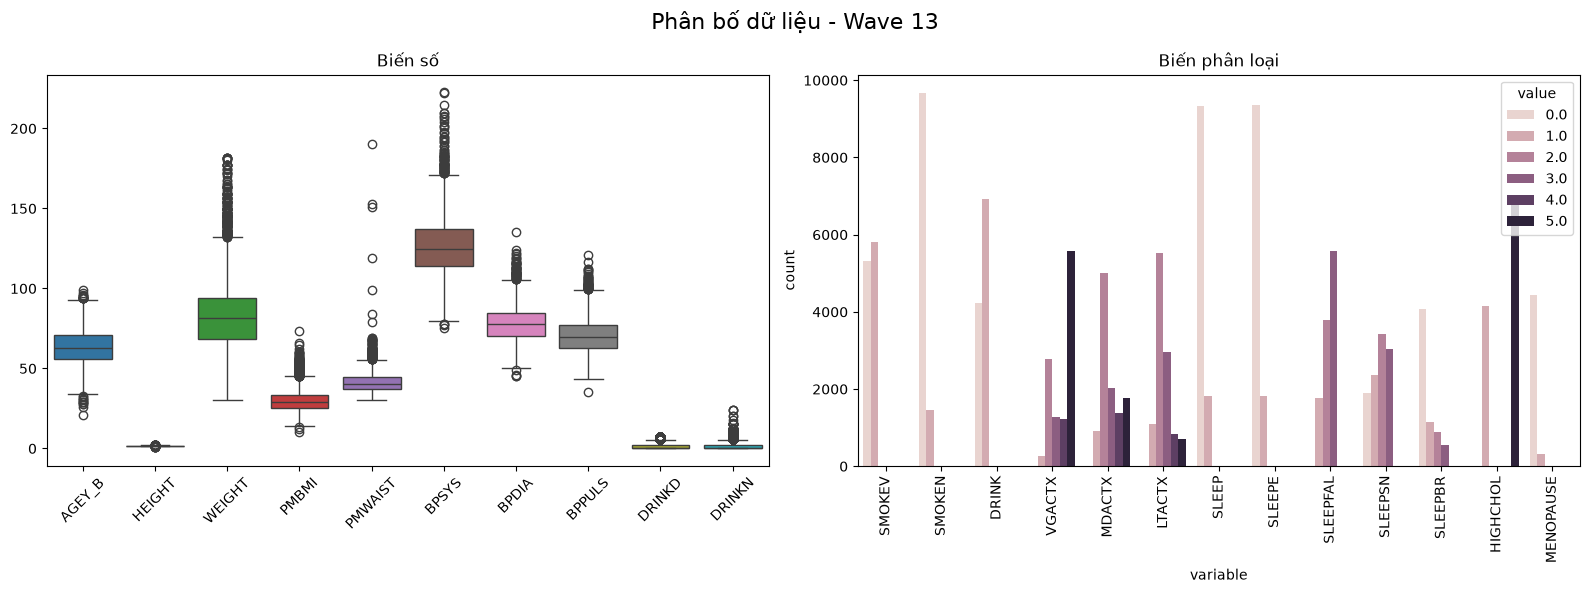

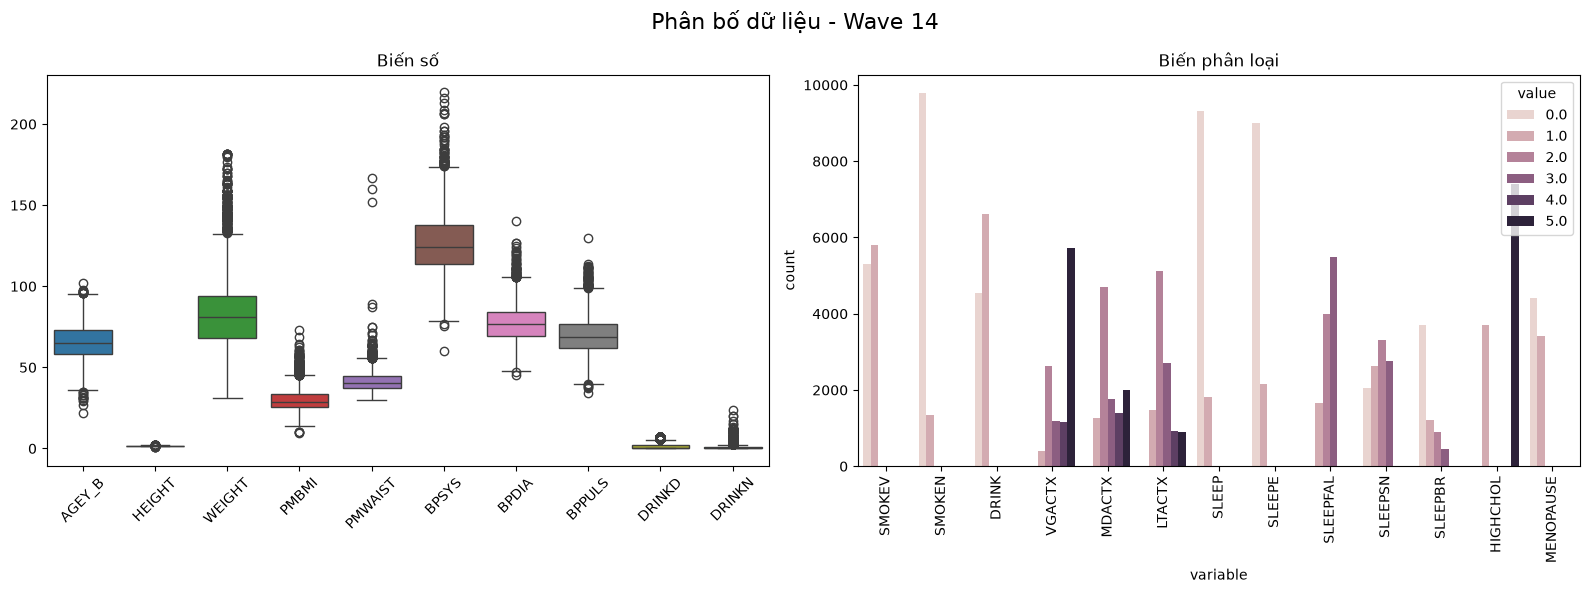

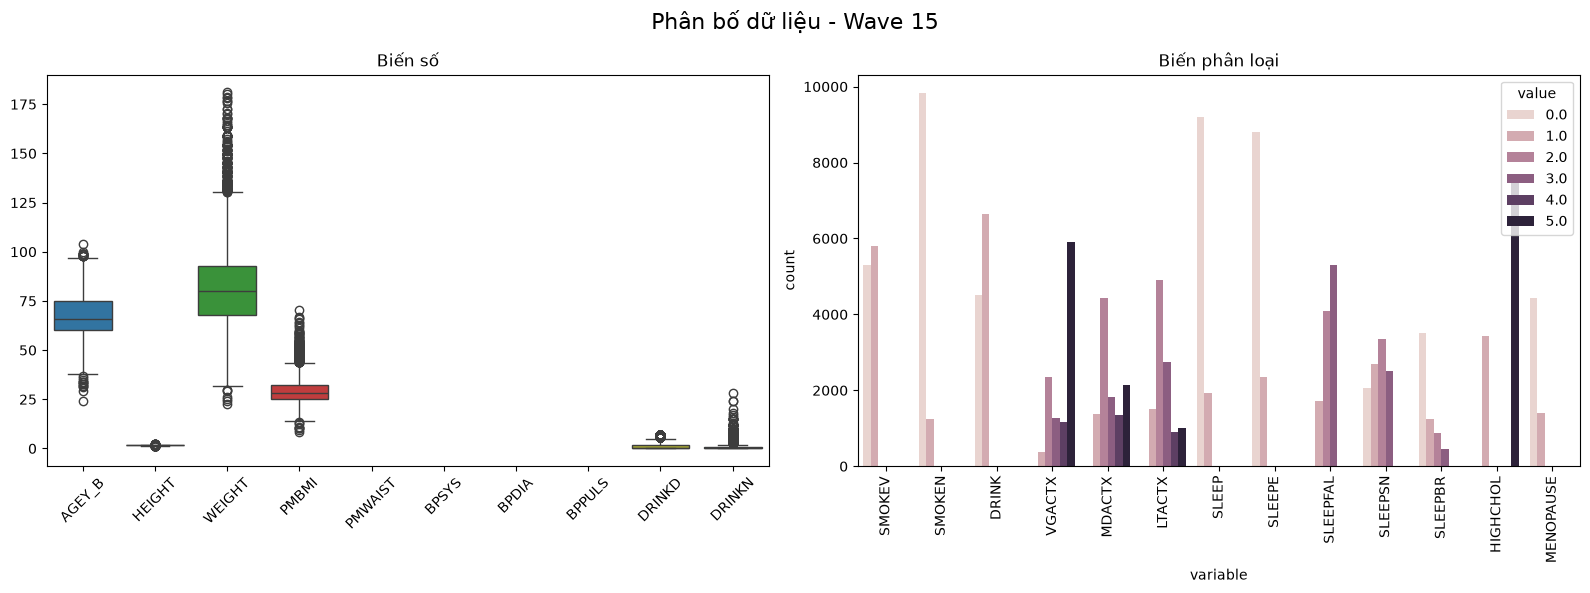

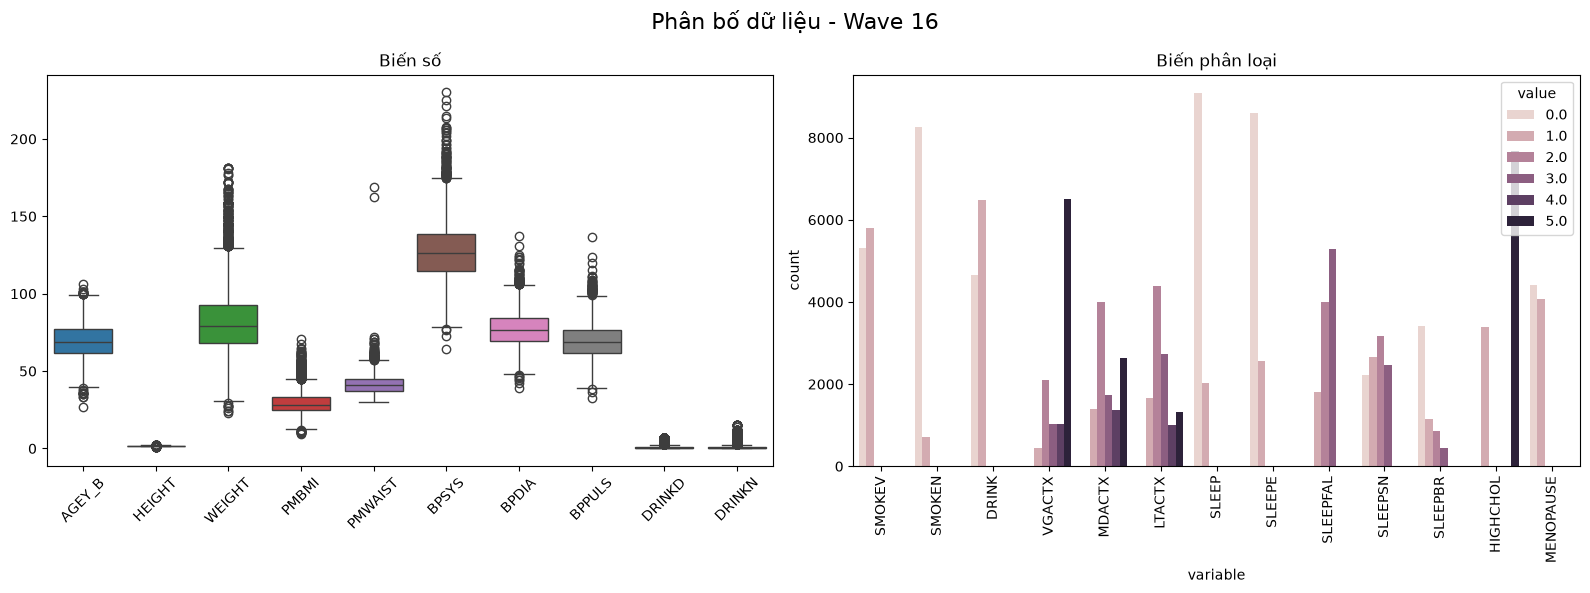

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = r"D:\2026\MedCare\ML\Dataset\Clean\merged_labeled.csv"
df = pd.read_csv(path)

# Biến số
numeric = [
    "AGEY_B", "HEIGHT", "WEIGHT", "PMBMI", "PMWAIST",
    "BPSYS", "BPDIA", "BPPULS", "DRINKD", "DRINKN"
]

# Biến phân loại
categorical = [
    "SMOKEV", "SMOKEN", "DRINK",
    "VGACTX", "MDACTX", "LTACTX",
    "SLEEP", "SLEEPE", "SLEEPFAL", "SLEEPSN", "SLEEPBR",
    "HIGHCHOL", "MENOPAUSE"
]

# Vẽ từng wave
for w in range(13, 17):

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle(f"Phân bố dữ liệu - Wave {w}", fontsize=16)

    # =========================
    # Biến số
    # =========================
    data_num = []

    for col in numeric:
        name = f"R{w}{col}" if f"R{w}{col}" in df.columns else col
        if name in df.columns:
            data_num.append(df[name].dropna().rename(col))

    if data_num:
        sns.boxplot(data=pd.concat(data_num, axis=1), ax=axes[0])
        axes[0].set_title("Biến số")
        axes[0].tick_params(axis="x", rotation=45)

    # =========================
    # Biến phân loại
    # =========================
    rows = []

    for col in categorical:
        name = f"R{w}{col}" if f"R{w}{col}" in df.columns else col
        if name in df.columns:
            rows.append(
                df[name]
                .value_counts()
                .rename_axis("value")
                .reset_index(name="count")
                .assign(variable=col)
            )

    if rows:
        cat = pd.concat(rows)
        sns.barplot(
            data=cat,
            x="variable",
            y="count",
            hue="value",
            ax=axes[1]
        )
        axes[1].set_title("Biến phân loại")
        axes[1].tick_params(axis="x", rotation=90)

    plt.tight_layout()
    plt.show()

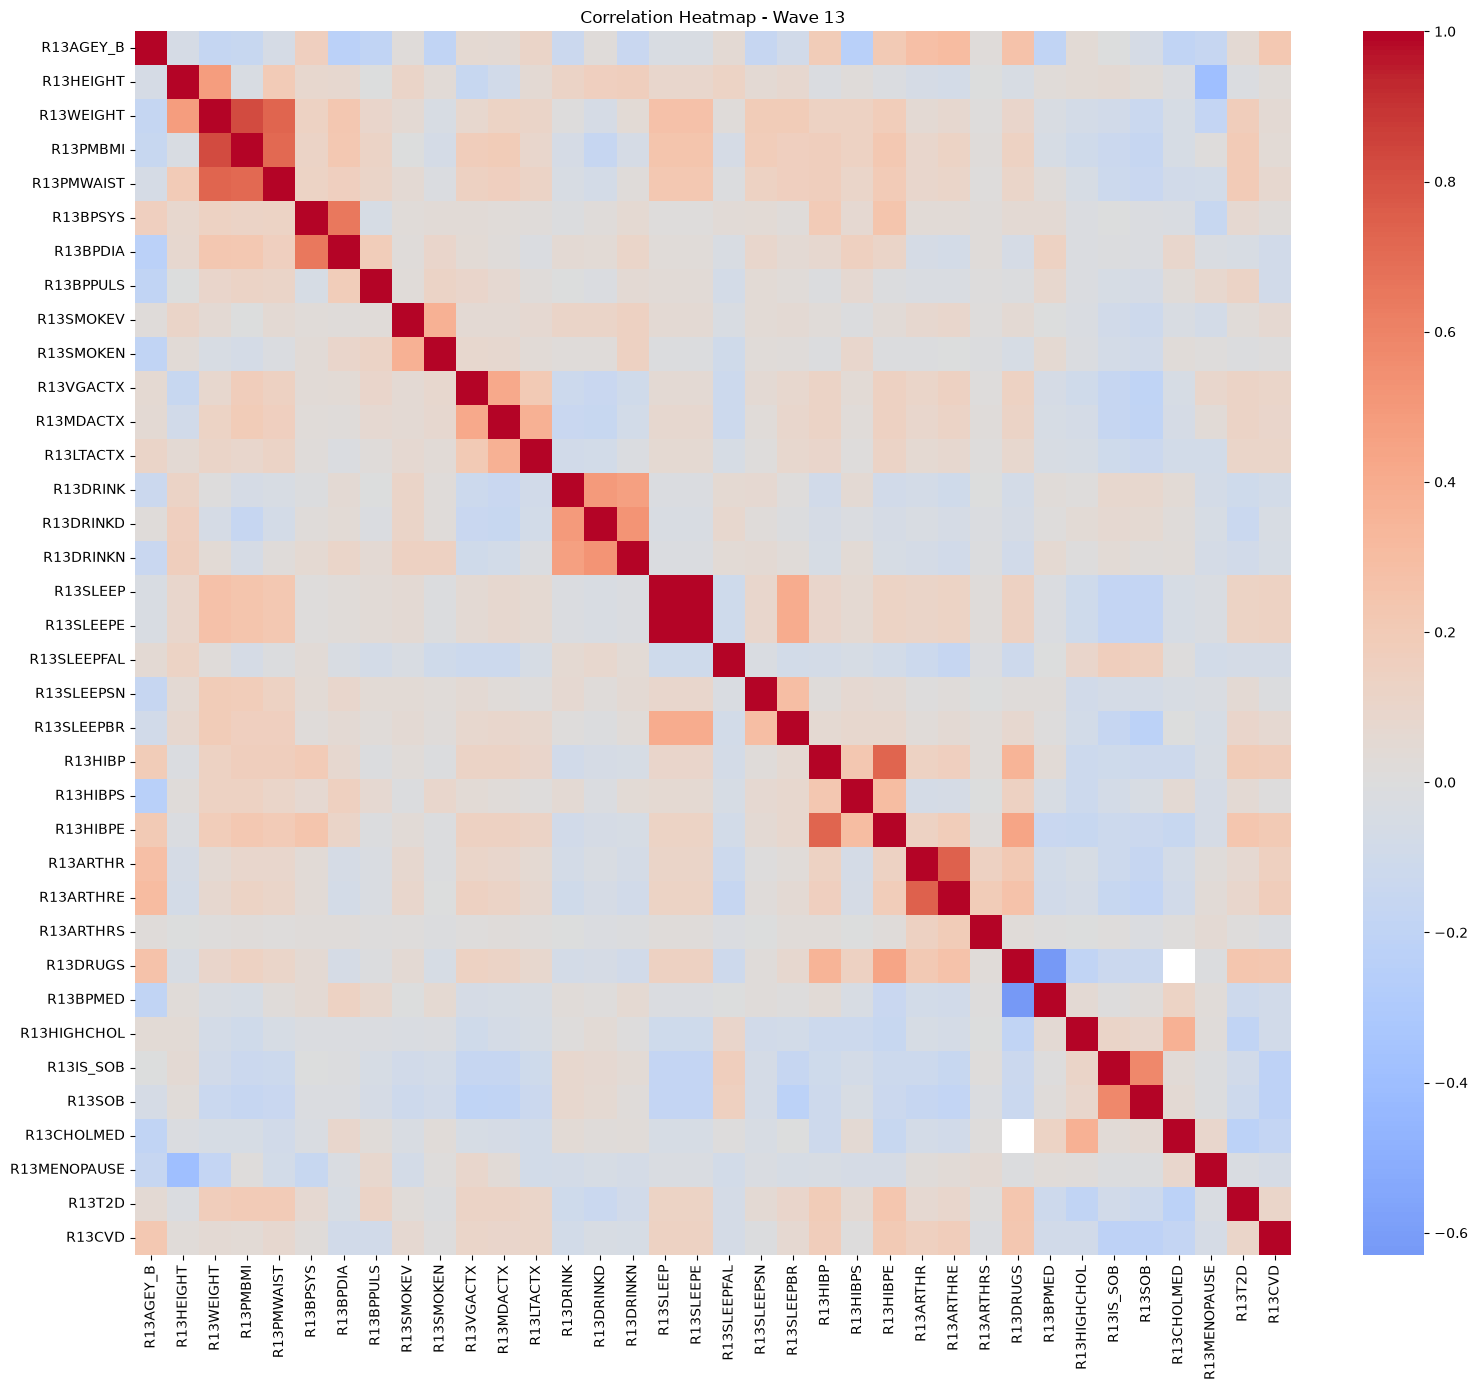

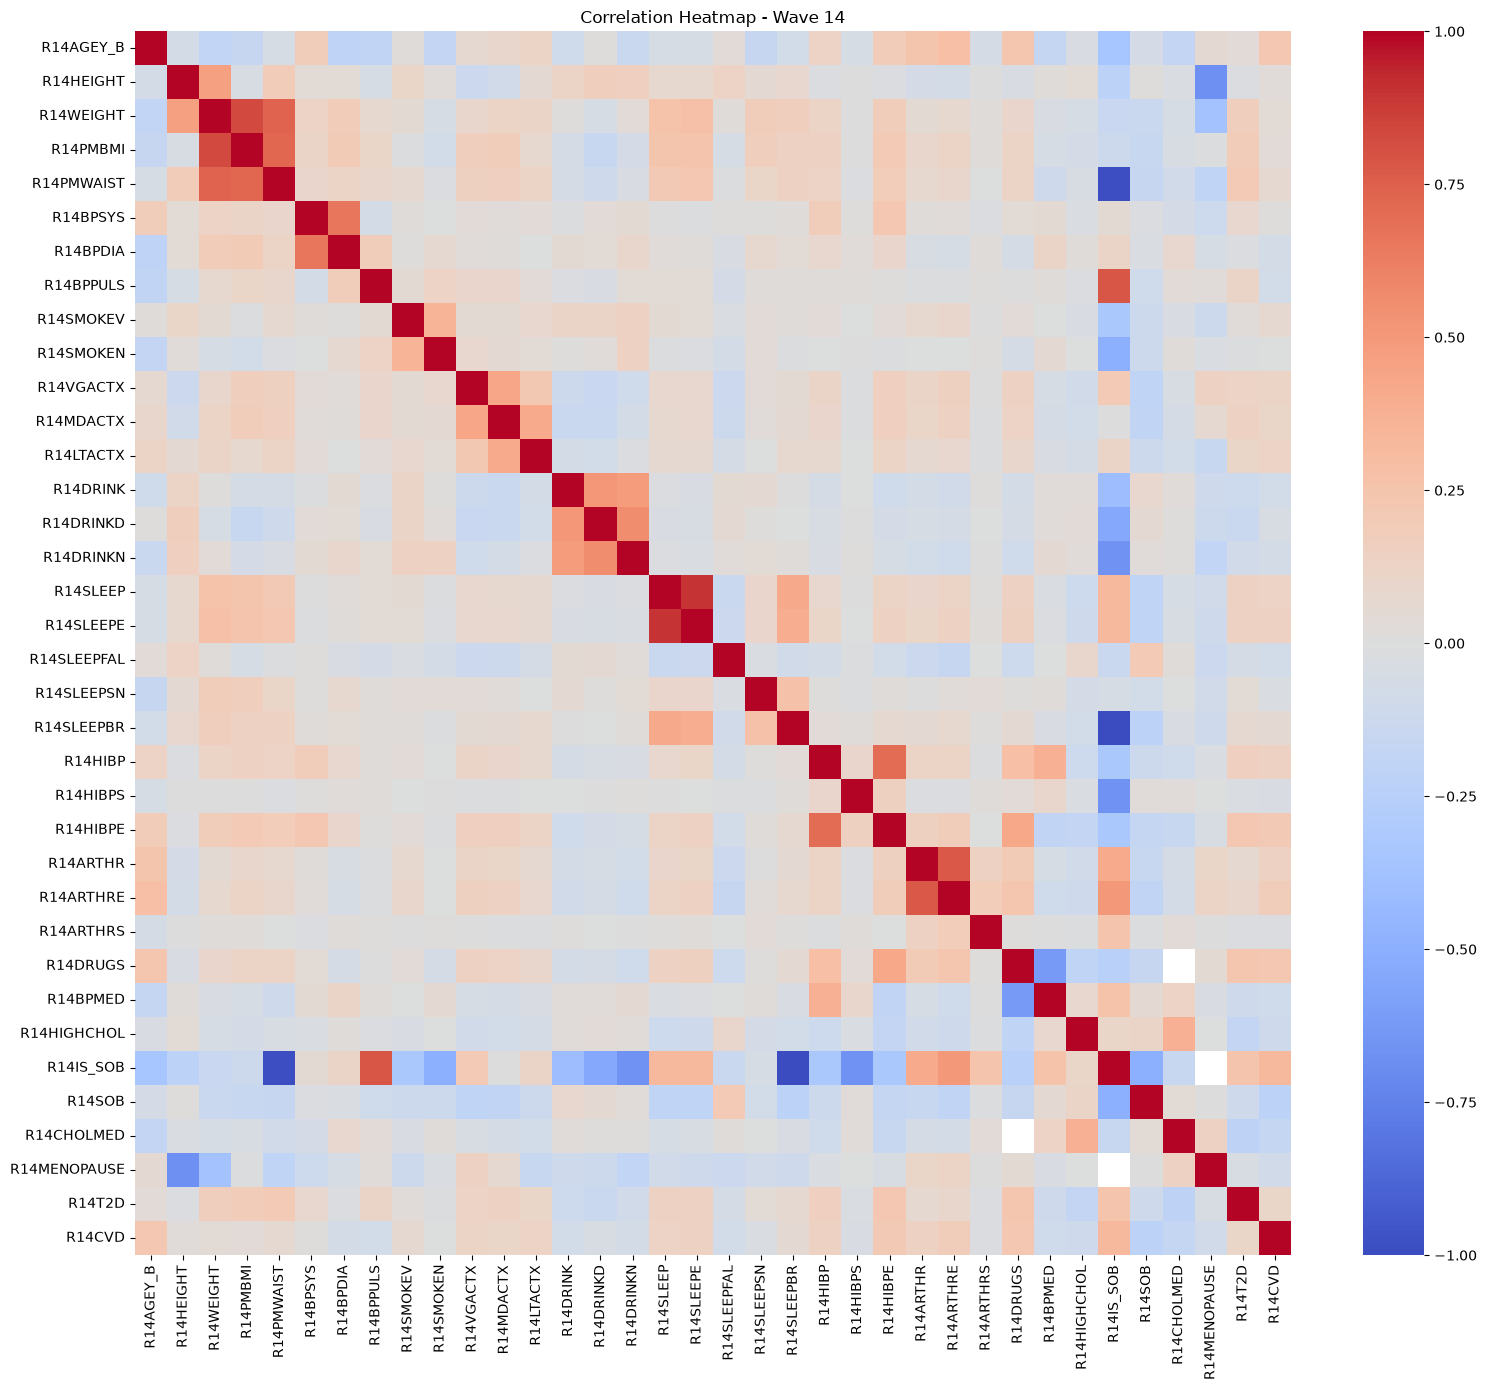

KeyboardInterrupt: 

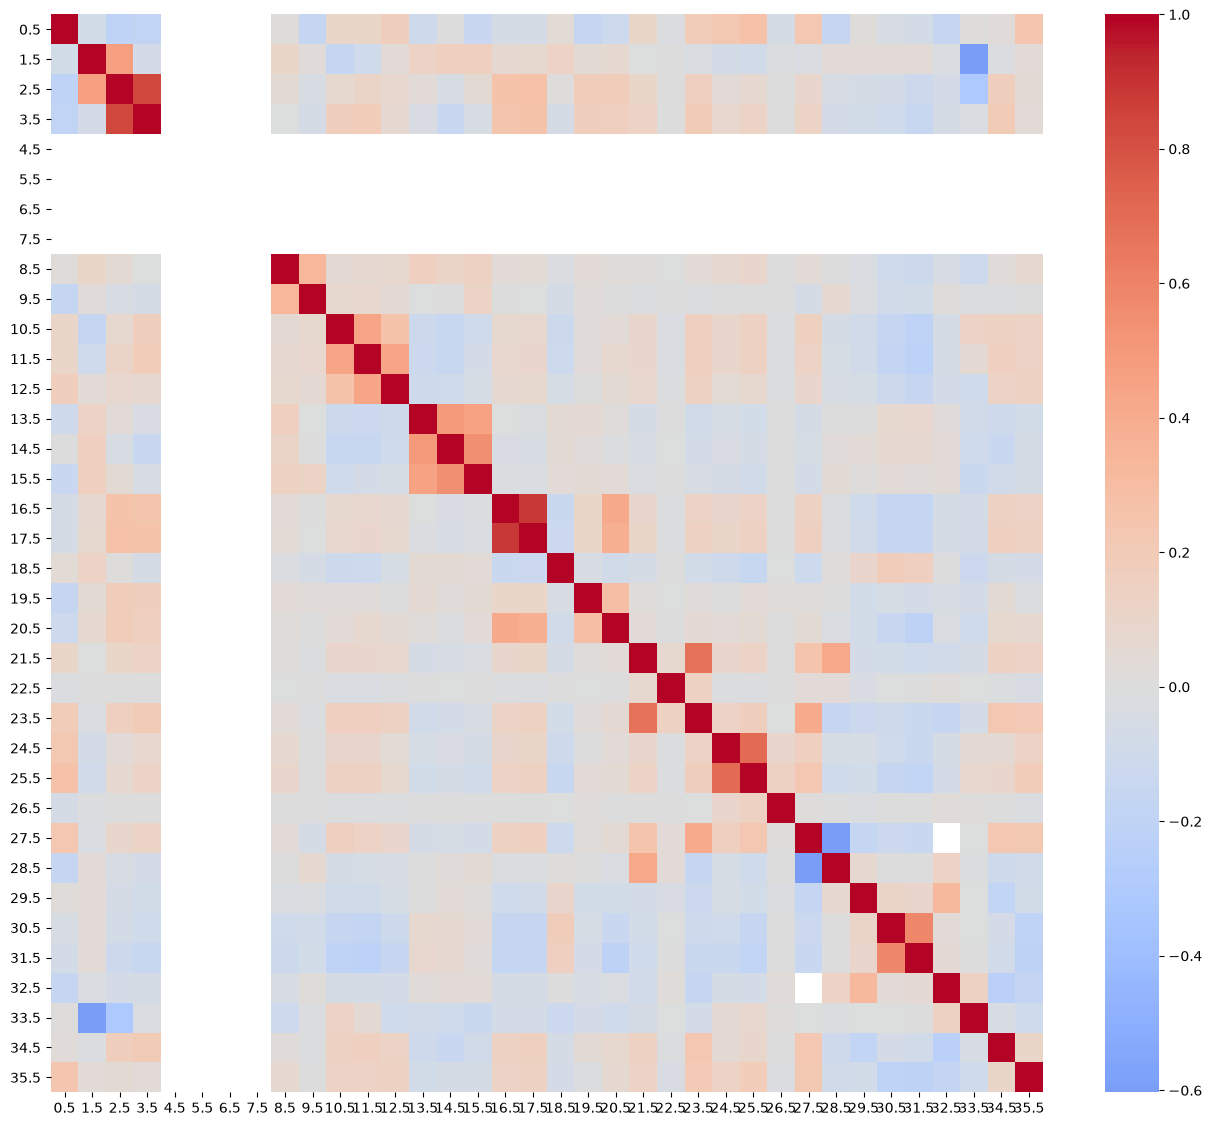

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

path = r"D:\2026\MedCare\ML\Dataset\Clean\merged_labeled.csv"
df = pd.read_csv(path)

for w in range(13, 17):
    prefix = f"R{w}"
    cols = [c for c in df.columns if c.startswith(prefix)]

    corr = df[cols].corr()

    plt.figure(figsize=(16, 14))
    sns.heatmap(corr, cmap="coolwarm", center=0)
    plt.title(f"Correlation Heatmap - Wave {w}")
    plt.tight_layout()
    plt.show()